# Experimentos numéricos — análisis de resultados

Reproduce las tablas y figuras a partir de `results/resultados_replicas.csv` (generado por `run_experiments.py`).
El diseño (factores, escenarios, métodos y estadística) está descrito en `README.md`.

In [1]:
import json
import pandas as pd
from IPython.display import Image, display
import analisis as A

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
d = A.cargar()
print(json.dumps(json.load(open("results/entorno.json")), indent=1, ensure_ascii=False))
print("Filas:", len(d), "· corridas:", d.groupby(["escenario", "semilla"]).ngroups)

{
 "python": "3.13.18",
 "so": "Linux-6.18.44-fc-v310-x86_64-with-glibc2.39",
 "cpu_nucleos": 4,
 "numpy": "2.5.3",
 "pandas": "3.0.5",
 "scikit_learn": "1.9.1",
 "xgboost": "3.4.1",
 "scipy": "1.18.1",
 "semillas": [
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30
 ],
 "semillas_barrido": [
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10
 ],
 "escenarios": {
  "tipico": {
   "magnitud": "1.0",
   "ruido": "1",
   "desgaste": "None",
   "faltantes": "0.0"
  },
  "borde": {
   "magnitud": "0.5",
   "ruido": "2",
   "desgaste": "(0.5, 2.0)",
   "faltantes": "0.0"
  },
  "extremo": {
   "magnitud": "0.25",
   "ruido": "3",
   "desgaste": "(0.5, 2.0)",
   "faltantes": "0.0"
  },
  "patologico": {
   "magnitud": "0.25",
   "ruido": "3",
   "desgaste": "(0.2, 0.6)",
   "faltantes": "0.3"
  }
 },
 "barrido_magnitud": [
  1.0,
  0.75,
  0.5,
  0.35,
  0.25,
  0.15
 ]
}
Fi

## 1. Resumen por escenario (media ± desviación, 30 réplicas)

In [2]:
res = A.resumen(d)
clave = ["auc_1d", "auc_3d", "mae_h", "rmse_h", "r2", "f1_alerta", "pct_fallas_con_alerta", "pct_normal_en_critico",
         "accuracy", "acc_bal", "f1_macro", "pct_fallas_causa_correcta"]
t = res[res.metrica.isin(clave)].assign(valor=lambda x: x.media.round(3).astype(str) + " ± " + x.desv.round(3).astype(str))
t.pivot_table(index=["tarea", "metrica", "metodo"], columns="escenario", values="valor", aggfunc="first")[A.ESCENARIOS]

escenario                                                                        tipico            borde          extremo       patologico
tarea metrica                   metodo                                                                                                    
rul   auc_1d                    RUL · Ridge (línea base)                  0.972 ± 0.031      0.82 ± 0.06     0.761 ± 0.06    0.513 ± 0.068
                                RUL · XGBoost (propuesto)                 0.969 ± 0.034    0.796 ± 0.051    0.726 ± 0.055    0.512 ± 0.047
                                RUL · promedio (ingenuo)                      0.5 ± 0.0        0.5 ± 0.0        0.5 ± 0.0        0.5 ± 0.0
      auc_3d                    RUL · Ridge (línea base)                  0.831 ± 0.063     0.61 ± 0.049    0.596 ± 0.052    0.503 ± 0.047
                                RUL · XGBoost (propuesto)                 0.838 ± 0.058    0.602 ± 0.042    0.579 ± 0.039      0.5 ± 0.035
                                RUL · promedio (ingenuo)                      0.5 ± 0.0        0.5 ± 0.0        0.5 ± 0.0        0.5 ± 0.0
      f1_alerta                 RUL · Ridge (línea base)                   0.42 ± 0.152     0.21 ± 0.127    0.064 ± 0.065        0.0 ± 0.0
                                RUL · XGBoost (propuesto)                  0.58 ± 0.098    0.482 ± 0.099    0.356 ± 0.102    0.002 ± 0.006
                                RUL · promedio (ingenuo)                      0.0 ± 0.0        0.0 ± 0.0        0.0 ± 0.0        0.0 ± 0.0
      mae_h                     RUL · Ridge (línea base)                 25.342 ± 2.214   31.771 ± 0.825   32.399 ± 0.832   34.071 ± 0.217
                                RUL · XGBoost (propuesto)                21.396 ± 2.214   30.601 ± 1.031   31.677 ± 0.998   34.343 ± 0.522
                                RUL · promedio (ingenuo)                   34.024 ± 0.0     34.024 ± 0.0     34.024 ± 0.0     34.024 ± 0.0
      pct_fallas_con_alerta     RUL · Ridge (línea base)                49.444 ± 18.301  36.111 ± 18.091   12.778 ± 13.62        0.0 ± 0.0
                                RUL · XGBoost (propuesto)                75.556 ± 10.48  63.889 ± 14.571     45.0 ± 7.768        0.0 ± 0.0
                                RUL · promedio (ingenuo)                      0.0 ± 0.0        0.0 ± 0.0        0.0 ± 0.0        0.0 ± 0.0
      pct_normal_en_critico     RUL · Ridge (línea base)                  0.043 ± 0.054    0.074 ± 0.055    0.021 ± 0.039        0.0 ± 0.0
                                RUL · XGBoost (propuesto)                  0.052 ± 0.08    0.146 ± 0.264    0.157 ± 0.279    0.008 ± 0.023
                                RUL · promedio (ingenuo)                      0.0 ± 0.0        0.0 ± 0.0        0.0 ± 0.0        0.0 ± 0.0
      r2                        RUL · Ridge (línea base)                  0.304 ± 0.119    0.002 ± 0.045   -0.015 ± 0.048   -0.113 ± 0.013
                                RUL · XGBoost (propuesto)                   0.4 ± 0.118   -0.004 ± 0.058    -0.04 ± 0.059   -0.167 ± 0.028
                                RUL · promedio (ingenuo)                   -0.107 ± 0.0     -0.107 ± 0.0     -0.107 ± 0.0     -0.107 ± 0.0
      rmse_h                    RUL · Ridge (línea base)                 31.065 ± 2.716   37.337 ± 0.845    37.65 ± 0.887   39.431 ± 0.228
                                RUL · XGBoost (propuesto)                28.819 ± 2.863    37.439 ± 1.07   38.103 ± 1.088   40.383 ± 0.482
                                RUL · promedio (ingenuo)                   39.334 ± 0.0     39.334 ± 0.0     39.334 ± 0.0     39.334 ± 0.0
tipo  acc_bal                   Tipo · XGBoost (propuesto)                0.859 ± 0.108    0.578 ± 0.066     0.458 ± 0.06    0.267 ± 0.018
                                Tipo · reglas del tablero (línea base)    0.705 ± 0.105    0.319 ± 0.046    0.256 ± 0.014    0.252 ± 0.008
      accuracy                  Tipo · XGBoost (propuesto)                0.965 ± 0.018    0.849 ± 0.027    

## 2. Propuesto frente a línea base (pareado por semilla, corrección de Holm)

In [3]:
pr = A.pruebas(d)
pr[["escenario", "metrica", "media_propuesto", "media_linea_base", "diferencia", "dif_ic95_inf", "dif_ic95_sup",
    "shapiro_p", "prueba", "p", "p_holm", "d_cohen", "gana_propuesto", "significativo_0.05"]].round(4)

,escenario,metrica,media_propuesto,media_linea_base,diferencia,dif_ic95_inf,dif_ic95_sup,shapiro_p,prueba,p,p_holm,d_cohen,gana_propuesto,significativo_0.05
0,tipico,auc_1d,0.9687,0.9721,-0.0034,-0.0091,0.0024,0.0890,t pareada,0.2432,0.4863,-0.2175,False,False
1,tipico,mae_h,21.3960,25.3425,-3.9465,-4.4369,-3.4561,0.6503,t pareada,0.0000,0.0000,-3.0051,True,True
2,tipico,f1_alerta,0.5800,0.4198,0.1602,0.1116,0.2089,0.0754,t pareada,0.0000,0.0000,1.2292,True,True
3,tipico,f1_macro,0.8676,0.7443,0.1234,0.0892,0.1575,0.5683,t pareada,0.0000,0.0000,1.3495,True,True
4,tipico,acc_bal,0.8588,0.7050,0.1537,0.1201,0.1874,0.6606,t pareada,0.0000,0.0000,1.7057,True,True
5,tipico,pct_fallas_causa_correcta,97.2222,91.6667,5.5556,-0.1841,11.2952,0.0000,Wilcoxon,0.0356,0.1069,0.3614,True,False
6,borde,auc_1d,0.7956,0.8199,-0.0243,-0.0414,-0.0071,0.2780,t pareada,0.0071,0.0354,-0.5291,False,True
7,borde,mae_h,30.6007,31.7712,-1.1706,-1.4541,-0.8870,0.4593,t pareada,0.0000,0.0000,-1.5416,True,True
8,borde,f1_alerta,0.4821,0.2097,0.2723,0.2231,0.3216,0.6871,t pareada,0.0000,0.0000,2.0660,True,True
9,borde,f1_macro,0.5717,0.3373,0.2344,0.2087,0.2601,0.3771,t pareada,0.0000,0.0000,3.4090,True,True


## 3. Efecto del escenario sobre el modelo propuesto (Kruskal-Wallis)

In [4]:
A.efecto_escenario(d).round(4)

,metodo,metrica,H,p,mediana_tipico,mediana_borde,mediana_extremo,mediana_patologico
0,RUL · XGBoost (propuesto),auc_1d,104.9041,0.0,0.9794,0.8091,0.7207,0.5135
1,RUL · XGBoost (propuesto),mae_h,103.4992,0.0,21.2954,30.5157,31.8616,34.4032
2,Tipo · XGBoost (propuesto),f1_macro,109.2430,0.0,0.8850,0.5748,0.4447,0.2630


## 4. Curva de rendimiento frente a la magnitud de la falla

In [5]:
bar = A.barrido(d)
bar.pivot_table(index=["metodo", "metrica"], columns="magnitud", values="media").round(3)

magnitud                                                            0.15    0.25    0.35    0.50    0.75    1.00
metodo                                 metrica                                                                  
RUL · Ridge (línea base)               auc_1d                      0.798   0.871   0.915   0.945   0.963   0.971
                                       mae_h                      28.769  28.001  27.540  26.915  26.131  25.632
RUL · XGBoost (propuesto)              auc_1d                      0.822   0.875   0.906   0.940   0.961   0.966
                                       mae_h                      27.685  26.193  25.195  24.076  22.761  22.098
RUL · promedio (ingenuo)               auc_1d                      0.500   0.500   0.500   0.500   0.500   0.500
                                       mae_h                      34.024  34.024  34.024  34.024  34.024  34.024
Tipo · XGBoost (propuesto)             f1_macro                    0.530   0.604   0.666   0.745   0.805   0.848
                                       pct_fallas_causa_correcta  80.000  81.667  85.000  95.000  93.333  95.000
Tipo · reglas del tablero (línea base) f1_macro                    0.228   0.267   0.349   0.506   0.647   0.739
                                       pct_fallas_causa_correcta   3.333  11.667  28.333  60.000  80.000  93.333

## 5. Figuras

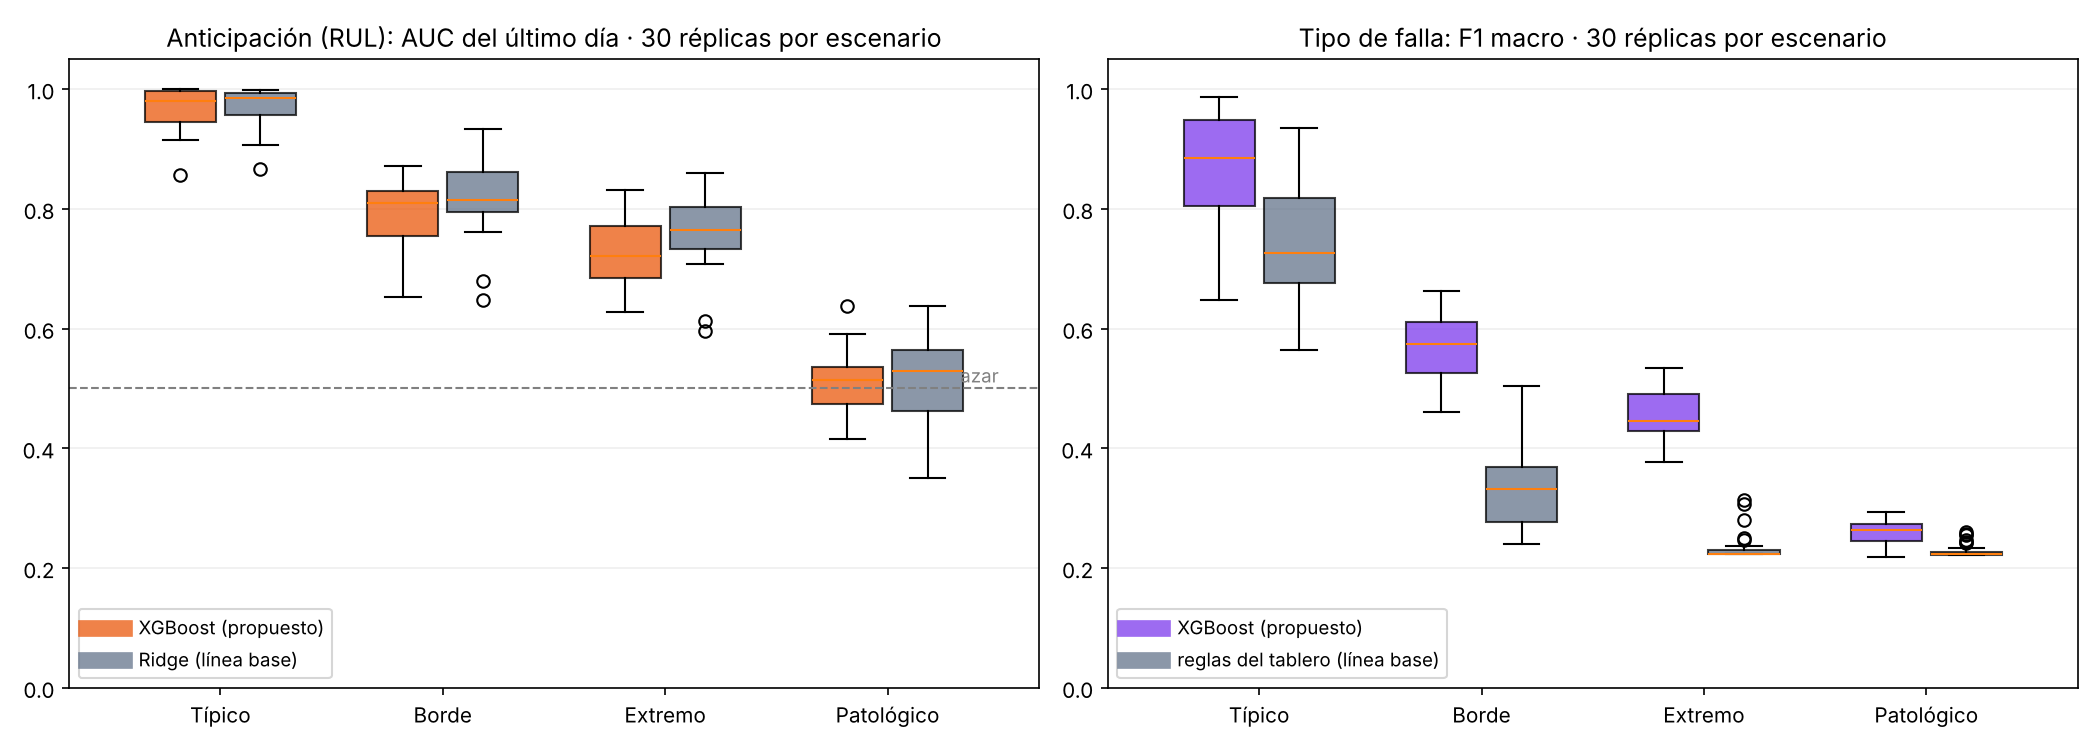

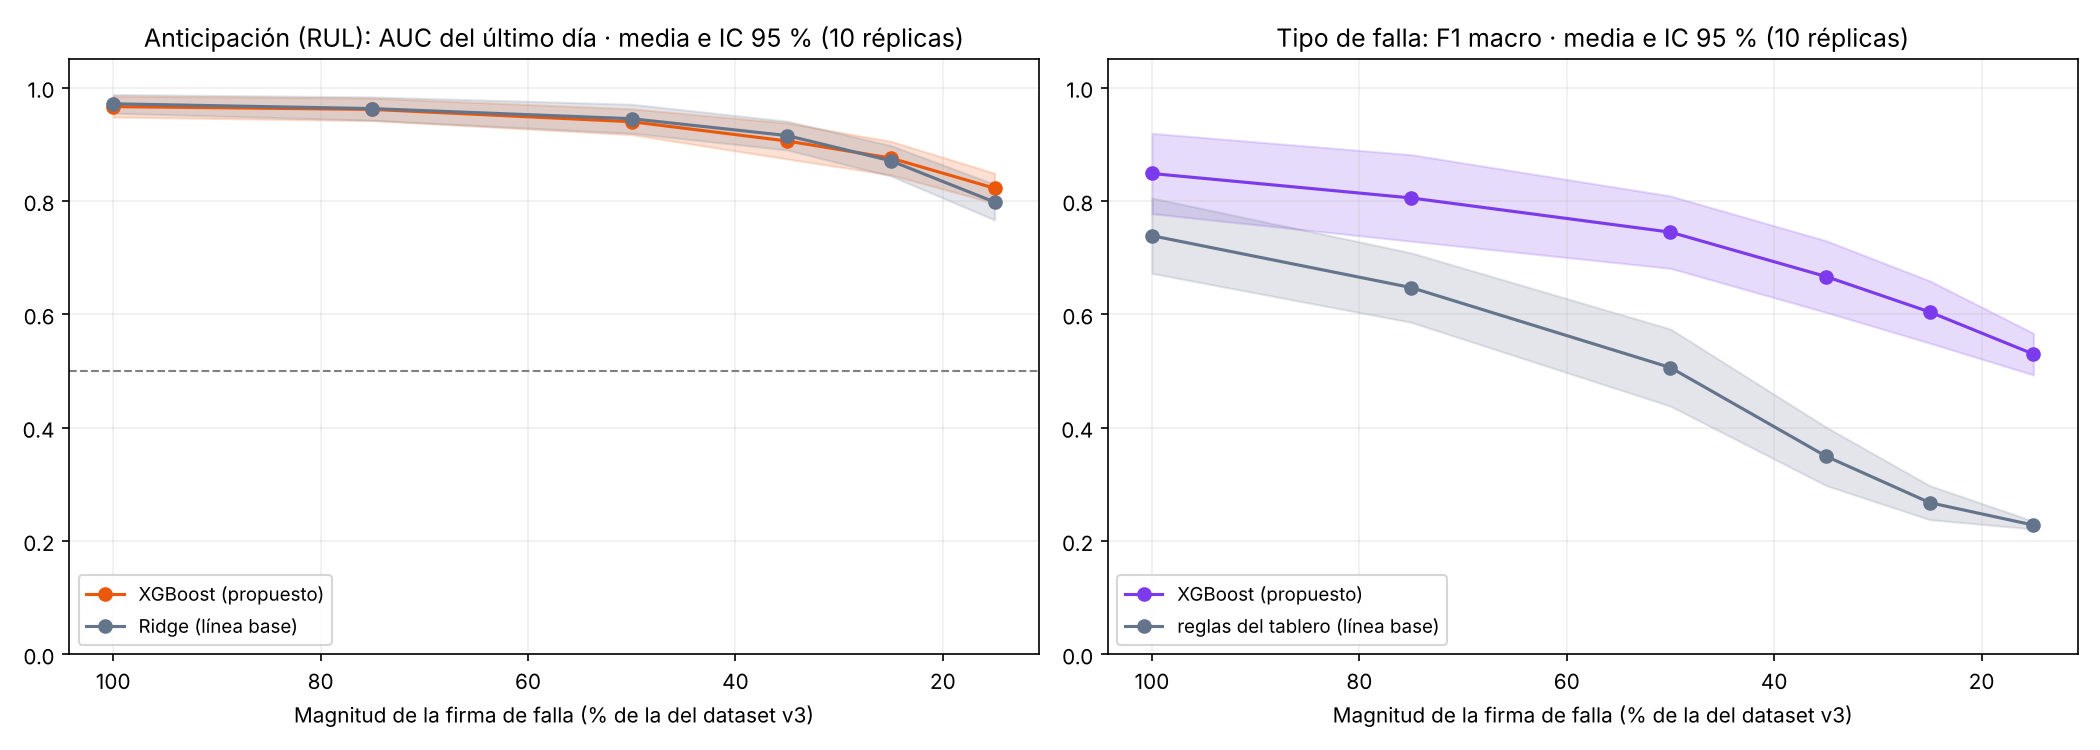

In [6]:
A.graficos(d, bar)
display(Image("results/boxplots_escenarios.png"))
display(Image("results/curva_magnitud.png"))